In [126]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense

# Import Data

In [101]:
import pandas as pd
import yfinance as yf

# Define the tickers for the indices
uk_ticker = '^FTSE'     # FTSE 100 (UK)
in_ticker = '^NSEI'         # NIFTY 50 (India)
jp_ticker = '^N225'         # Nikkei 225 (Japan)
us_ticker = '^GSPC' # S&P 500

# Define the date range
start_date: '2019-04-04'
end_date: '2024-04-04'


# Download the data using yfinance
uk_data = yf.download(uk_ticker, start=start_date, end=end_date, interval='1wk')
in_data = yf.download(in_ticker, start=start_date, end=end_date, interval='1wk')
jp_data = yf.download(jp_ticker, start=start_date, end=end_date, interval='1wk')
us_data = yf.download(us_ticker, start='2019-04-04', end='2024-04-04', interval='1wk')

[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed
[*********************100%%**********************]  1 of 1 completed


In [102]:
# Convert index to datetime format
uk_data.index = pd.to_datetime(uk_data.index)
in_data.index = pd.to_datetime(in_data.index)
jp_data.index = pd.to_datetime(jp_data.index)
us_data.index = pd.to_datetime(us_data.index)

In [103]:
# Check if the missing date '2019-04-29' is present
if '2019-04-29' not in jp_data.index:
    # Fill missing data for '2019-04-29' with the value from the previous week
    previous_week_data = jp_data.loc['2019-04-22']
    jp_data.loc['2019-04-29'] = previous_week_data

    print("The missing date '2019-04-29' has been filled with data from the previous week.")
else:
    print("The missing date '2019-04-29' is already present.")

The missing date '2019-04-29' has been filled with data from the previous week.


In [104]:
import numpy as np
import pandas as pd

def calculate_technical_indicators(index_data):
    # Calculate RSI (Relative Strength Index)
    delta = index_data['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    rsi = 100 - (100 / (1 + rs))

    # Calculate Stochastic Oscillator
    low_min = index_data['Low'].rolling(window=14).min()
    high_max = index_data['High'].rolling(window=14).max()
    k = 100 * ((index_data['Close'] - low_min) / (high_max - low_min))
    slowk = k.rolling(window=3).mean()
    slowd = slowk.rolling(window=3).mean()

    # Calculate MACD (Moving Average Convergence Divergence)
    exp1 = index_data['Close'].ewm(span=12).mean()
    exp2 = index_data['Close'].ewm(span=26).mean()
    macd = exp1 - exp2
    signal = macd.ewm(span=9).mean()

    # Calculate Bollinger Bands
    rolling_mean = index_data['Close'].rolling(window=5).mean()
    rolling_std = index_data['Close'].rolling(window=5).std()
    upper_band = rolling_mean + (rolling_std * 2)
    lower_band = rolling_mean - (rolling_std * 2)

    # Calculate EMA (Exponential Moving Average)
    ema = index_data['Close'].ewm(span=5).mean()

    # Store all calculated indicators in a DataFrame
    indicators_df = pd.DataFrame({
        'RSI': rsi,
        'Stochastic_SlowK': slowk,
        'Stochastic_SlowD': slowd,
        'MACD': macd,
        'MACD_Signal': signal,
        'Bollinger_Upper': upper_band,
        'Bollinger_Lower': lower_band,
        'EMA': ema
    }, index=index_data.index)

    # Combine indicators with original data
    combined_data = pd.concat([index_data, indicators_df], axis=1)

    return combined_data

# Build Features

In [105]:
# Assuming you have already loaded or created these DataFrames: uk_data, us_data, jap_data, ind_data, cn_data

# Combine all dataframes into a dictionary
stock_data = {
    'UK': uk_data,
    'US': us_data,
    'Japan': jp_data,
    'India': in_data,
}

# Calculate technical indicators
uk_data1 = calculate_technical_indicators(uk_data)
us_data1 = calculate_technical_indicators(us_data)
jp_data1 = calculate_technical_indicators(jp_data)
in_data1 = calculate_technical_indicators(in_data)


### Check if they work Properly

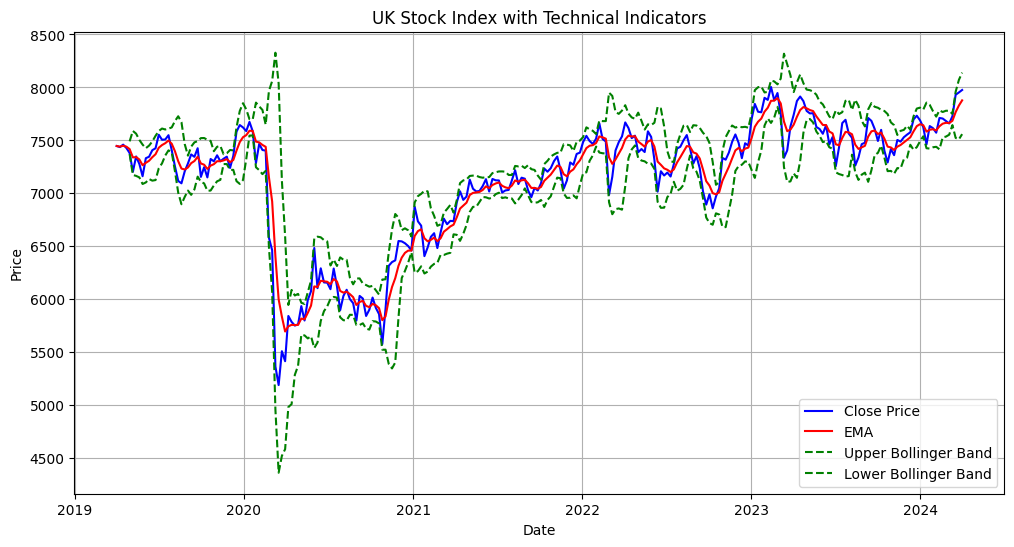

In [106]:
import matplotlib.pyplot as plt

# Assuming 'uk_data1' is the DataFrame containing technical indicators for the UK
# Plot 'Close' price along with some technical indicators
plt.figure(figsize=(12, 6))
plt.plot(uk_data1.index, uk_data1['Close'], label='Close Price', color='blue')
plt.plot(uk_data1.index, uk_data1['EMA'], label='EMA', color='red')
plt.plot(uk_data1.index, uk_data1['Bollinger_Upper'], label='Upper Bollinger Band', color='green', linestyle='--')
plt.plot(uk_data1.index, uk_data1['Bollinger_Lower'], label='Lower Bollinger Band', color='green', linestyle='--')
plt.title('UK Stock Index with Technical Indicators')
plt.xlabel('Date')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.show()


# Build the Target Variable

In [107]:
# Calculate returns for each dataset and store them in the DataFrame
uk_data1['Returns'] = (uk_data1['Close'] / uk_data1['Close'].shift(1) - 1) * 100
us_data1['Returns'] = (us_data1['Close'] / us_data1['Close'].shift(1) - 1) * 100
jp_data1['Returns'] = (jp_data1['Close'] / jp_data1['Close'].shift(1) - 1) * 100
in_data1['Returns'] = (in_data1['Close'] / in_data1['Close'].shift(1) - 1) * 100

In [108]:
# Calculate returns for each dataset
uk_returns = (uk_data1['Close'] / uk_data1['Close'].shift(1) - 1) * 100
us_returns = (us_data1['Close'] / us_data1['Close'].shift(1) - 1) * 100
jp_returns = (jp_data1['Close'] / jp_data1['Close'].shift(1) - 1) * 100
in_returns = (in_data1['Close'] / in_data1['Close'].shift(1) - 1) * 100

# Drop rows with NaN values
uk_returns.dropna(inplace=True)
us_returns.dropna(inplace=True)
jp_returns.dropna(inplace=True)
in_returns.dropna(inplace=True)


# Inter-Indice Impact

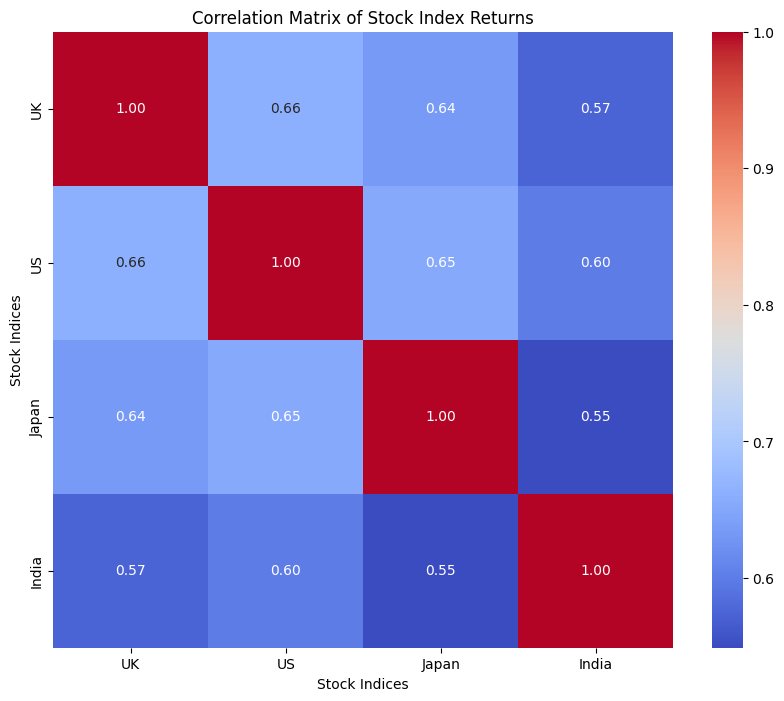

In [109]:
# Assuming you have calculated returns for each stock index
returns_data = {
    'UK': uk_returns,
    'US': us_returns,
    'Japan': jp_returns,
    'India': in_returns,
}

# Combine returns into a single DataFrame
returns_df = pd.DataFrame(returns_data)
returns_df['Japan'].fillna(method='ffill', inplace=True)

# Calculate correlation matrix
correlation_matrix = returns_df.corr()

# Visualize correlation matrix as a heatmap
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Stock Index Returns')
plt.xlabel('Stock Indices')
plt.ylabel('Stock Indices')
plt.show()


# CONCAT DATA

In [110]:
data = pd.concat([uk_data1, us_data1, jp_data1, in_data1], axis=1)
data

### Rename Columns to Avoid Confusion

In [112]:
def prepend_index_name(df, index_name):
    renamed_columns = [f"{index_name}_{col}" for col in df.columns]
    return df.rename(columns=dict(zip(df.columns, renamed_columns)))

# Example usage:
# Assuming df_uk is your DataFrame for the UK index
# Call the function to prepend 'UK' to each column name
uk_data_renamed = prepend_index_name(uk_data1, 'UK')
us_data_renamed = prepend_index_name(us_data1, 'US')
in_data_renamed = prepend_index_name(in_data1, 'India')
jp_data_renamed = prepend_index_name(jp_data1, 'Japan')

# Build the model

#### us uk jap on ind

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.2496
Epoch 2/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0304
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0360
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0242
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0151
Epoch 6/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0156
Epoch 7/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0139
Epoch 8/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0125
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0120
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0115
Epoch 11/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0111
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0107
Epoch 13/50
7/7 [==============================] - 0s 4ms/step - loss: 0.

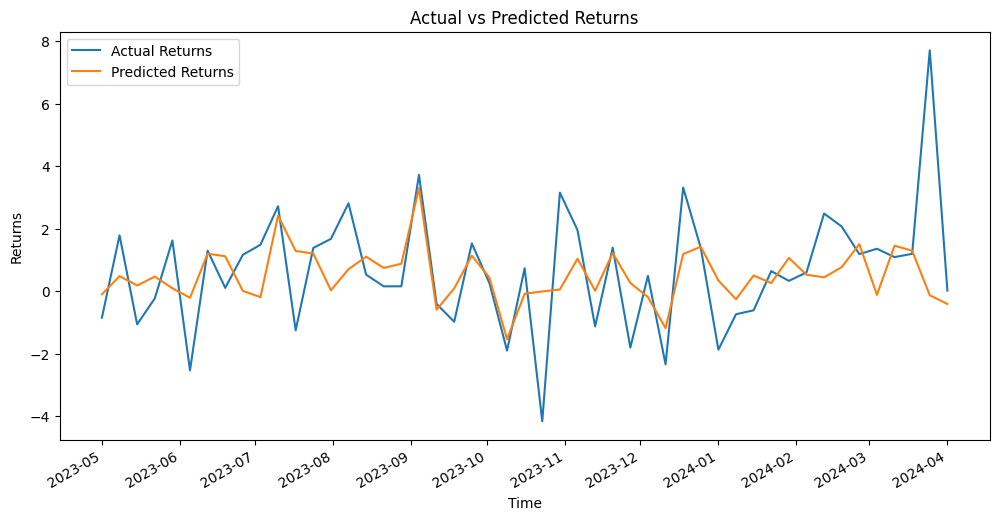

In [116]:
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, us_data_renamed, jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns=['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD',
                               'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper',
                               'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1, 1))  # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=3)

# Reshape input data for PyTorch (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))


import torch
import torch.nn as nn
import torch.optim as optim

# Define LSTM model in PyTorch
class LSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = self.fc(out[:, -1, :])  # Use the last output of the LSTM
        return out

# Define model parameters
input_size = X_train.shape[2]
hidden_size = 50
output_size = 1

# Initialize the model, loss function, and optimizer
model = LSTMModel(input_size, hidden_size, output_size)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Convert data to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32)

# Training loop
num_epochs = 50
batch_size = 32
train_losses = []

for epoch in range(num_epochs):
    model.train()
    optimizer.zero_grad()
    output = model(X_train_tensor)
    loss = criterion(output, y_train_tensor)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())
    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}")

# Evaluate the model
model.eval()
with torch.no_grad():
    predictions = model(X_test_tensor).numpy()
    test_loss = criterion(model(X_test_tensor), y_test_tensor).item()
    print(f"Test Loss: {test_loss}")

# Inverse transform the predictions and actual values
predictions = scaler.inverse_transform(predictions)
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], y_test_actual, label="Actual Returns", color="blue")
plt.plot(df_combined.index[-len(y_test):], predictions, label="Predicted Returns", color="red")
plt.title("Actual vs Predicted Returns (India on UK, US, Japan)")
plt.xlabel("Time")
plt.ylabel("Returns")
plt.legend()
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()

# Save the plot
plt.savefig("actual_vs_predicted_returns_india.png")
plt.show()


#### uk us ind on jap

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.0375
Epoch 2/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0251
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0177
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0130
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0109
Epoch 6/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0096
Epoch 7/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0087
Epoch 8/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0081
Epoch 9/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0072
Epoch 10/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0069
Epoch 11/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0066
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0061
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

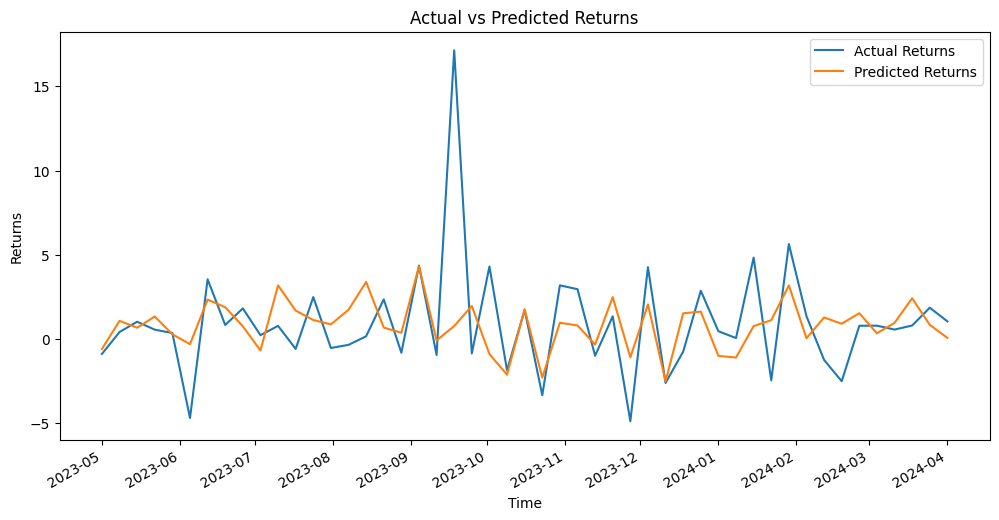

In [117]:
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, us_data_renamed, jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['Japan_RSI', 'Japan_Stochastic_SlowK', 'Japan_Stochastic_SlowD', 'Japan_MACD', 'Japan_MACD_Signal', 'Japan_Bollinger_Upper', 'Japan_Bollinger_Lower', 'Japan_EMA', 'Japan_Returns'])
y = df_combined['Japan_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()

#### us jap in on uk

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.1273
Epoch 2/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0467
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0384
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0256
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0242
Epoch 6/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0193
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0184
Epoch 8/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0161
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0149
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0137
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0129
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0123
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

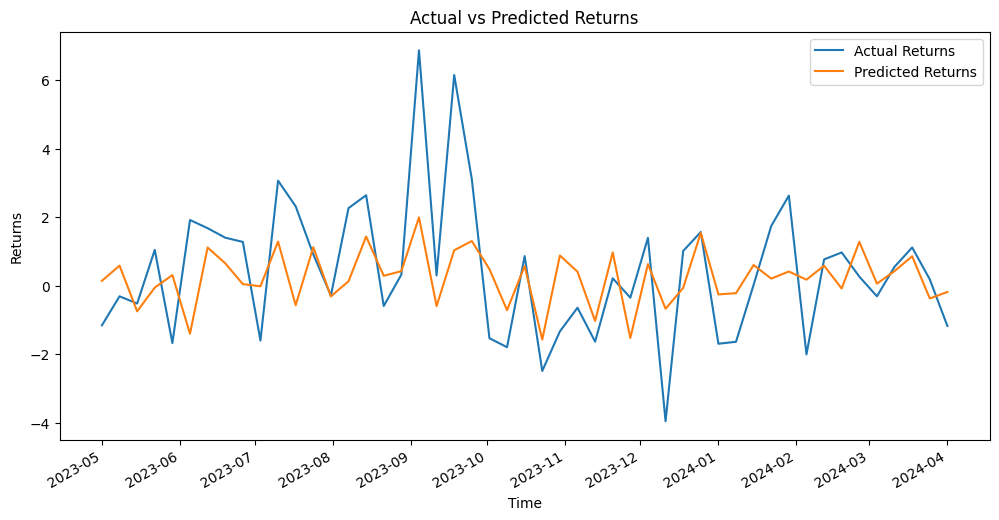

In [118]:
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, us_data_renamed, jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['UK_RSI', 'UK_Stochastic_SlowK', 'UK_Stochastic_SlowD', 'UK_MACD', 'UK_MACD_Signal', 'UK_Bollinger_Upper', 'UK_Bollinger_Lower', 'UK_EMA', 'UK_Returns'])
y = df_combined['UK_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns
import matplotlib.pyplot as plt

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()

#### in jap uk on us

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.0929
Epoch 2/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0379
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0231
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0195
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0176
Epoch 6/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0158
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0152
Epoch 8/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0145
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0141
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0135
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0131
Epoch 12/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0129
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

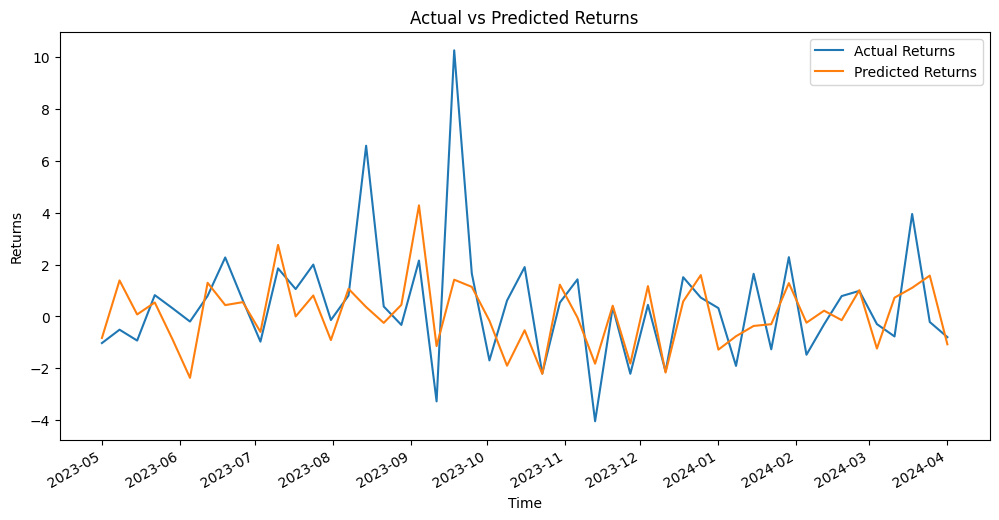

In [120]:
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, us_data_renamed, jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['US_RSI', 'US_Stochastic_SlowK', 'US_Stochastic_SlowD', 'US_MACD', 'US_MACD_Signal', 'US_Bollinger_Upper', 'US_Bollinger_Lower', 'US_EMA', 'US_Returns'])
y = df_combined['US_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()

## Indice Impact on India

#### uk us on ind

Epoch 1/50
7/7 [==============================] - 3s 4ms/step - loss: 0.1433
Epoch 2/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0315
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0416
Epoch 4/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0244
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0207
Epoch 6/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0179
Epoch 7/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0153
Epoch 8/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0150
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0132
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0124
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0117
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0111
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

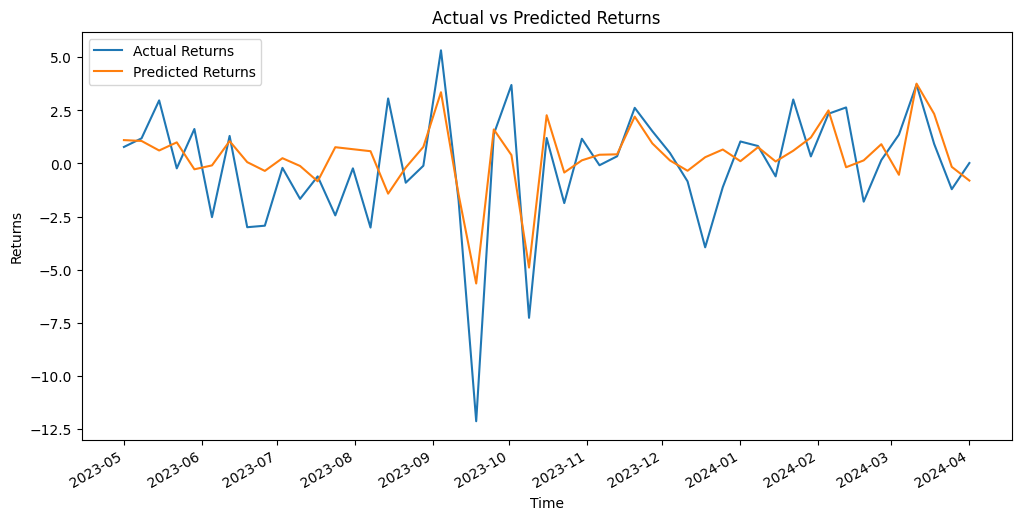

In [121]:
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, us_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD', 'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper', 'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()


#### us on ind

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.2014
Epoch 2/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0641
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0239
Epoch 4/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0288
Epoch 5/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0265
Epoch 6/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0192
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0171
Epoch 8/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0165
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0150
Epoch 10/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0142
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0135
Epoch 12/50
7/7 [==============================] - 0s 2ms/step - loss: 0.0131
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

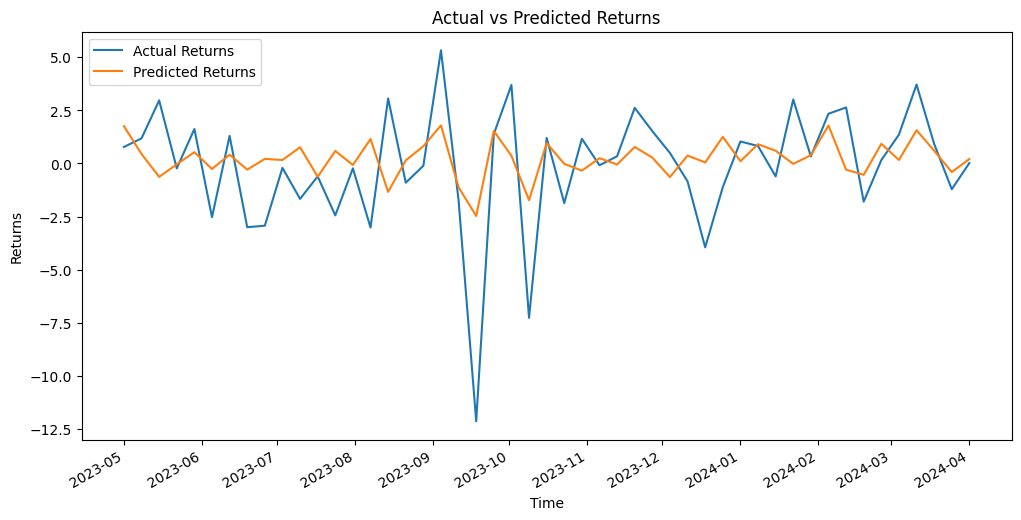

In [122]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense

# Assuming df_uk, df_us, df_japan, and df_india are DataFrames for the UK, US, Japan, and India indices, respectively
# Concatenate the DataFrames
df_combined = pd.concat([us_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD', 'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper', 'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()


### uk on ind

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.2324
Epoch 2/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0584
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0319
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0377
Epoch 5/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0275
Epoch 6/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0232
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0226
Epoch 8/50
7/7 [==============================] - 0s 2ms/step - loss: 0.0208
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0197
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0191
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0178
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0167
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

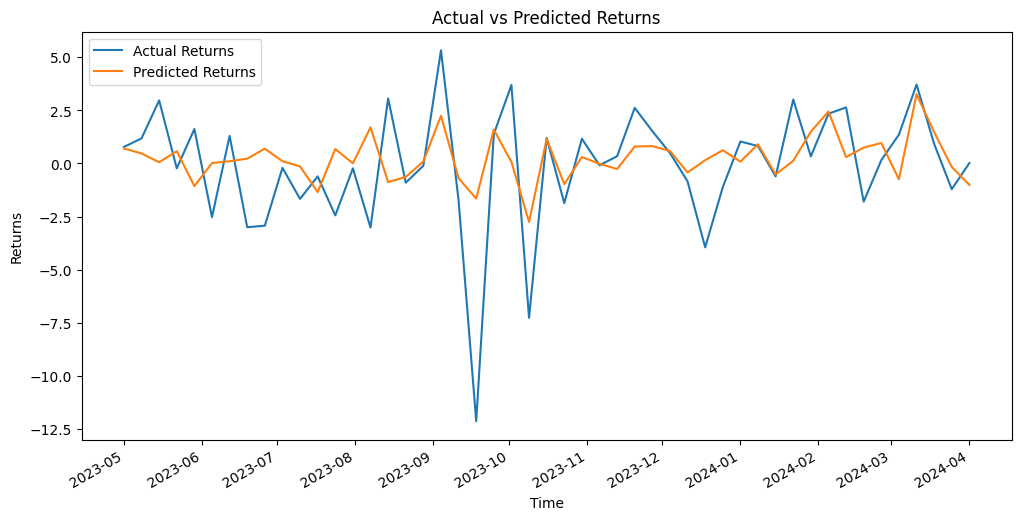

In [123]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense

# Assuming df_uk, df_us, df_japan, and df_india are DataFrames for the UK, US, Japan, and India indices, respectively
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD', 'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper', 'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()

#### jap on ind

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.1878
Epoch 2/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0679
Epoch 3/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0257
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0257
Epoch 5/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0255
Epoch 6/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0204
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0180
Epoch 8/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0171
Epoch 9/50
7/7 [==============================] - 0s 2ms/step - loss: 0.0162
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0154
Epoch 11/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0147
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0141
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

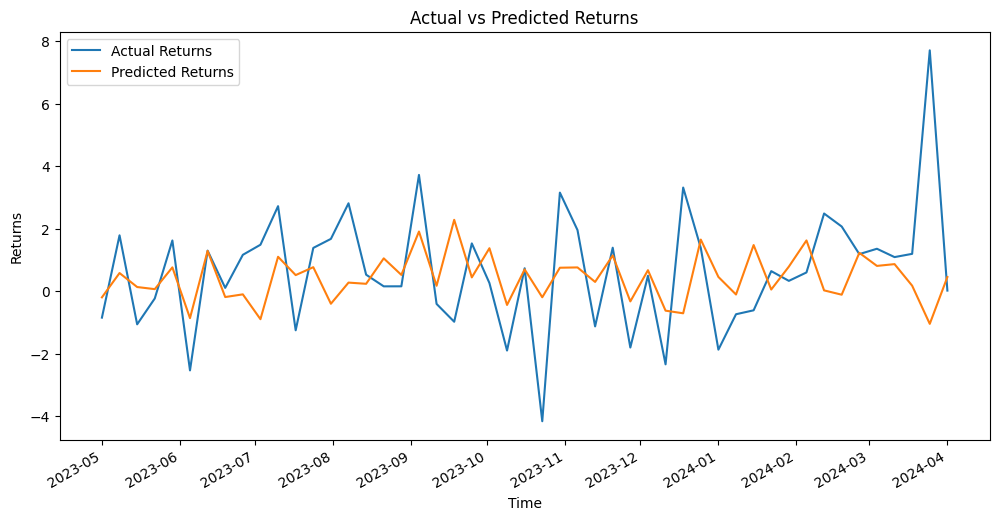

In [124]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense

# Assuming df_uk, df_us, df_japan, and df_india are DataFrames for the UK, US, Japan, and India indices, respectively
# Concatenate the DataFrames
df_combined = pd.concat([jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD', 'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper', 'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()

#### Uk jap on ind

Epoch 1/50
7/7 [==============================] - 2s 6ms/step - loss: 0.0828
Epoch 2/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0410
Epoch 3/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0230
Epoch 4/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0234
Epoch 5/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0179
Epoch 6/50
7/7 [==============================] - 0s 6ms/step - loss: 0.0153
Epoch 7/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0138
Epoch 8/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0129
Epoch 9/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0122
Epoch 10/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0116
Epoch 11/50
7/7 [==============================] - 0s 5ms/step - loss: 0.0109
Epoch 12/50
7/7 [==============================] - 0s 6ms/step - loss: 0.0104
Epoch 13/50
7/7 [==============================] - 0s 5ms/step - loss: 0.

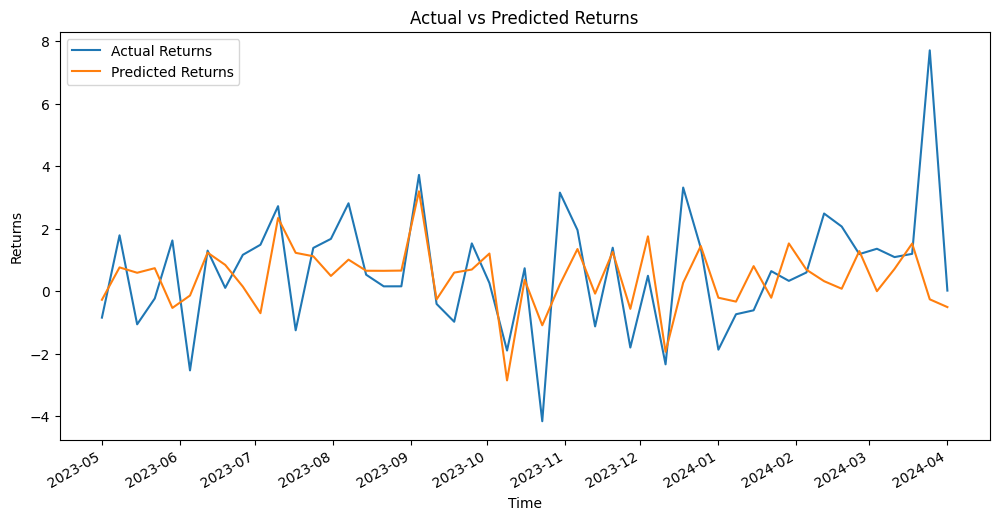

In [142]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import LSTM, Dense

# Assuming df_uk, df_us, df_japan, and df_india are DataFrames for the UK, US, Japan, and India indices, respectively
# Concatenate the DataFrames
df_combined = pd.concat([uk_data_renamed,jp_data_renamed, in_data_renamed], axis=1)

# Remove 'Adj Close' columns as they contain duplicate information with 'Close'
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variables
X = df_combined.drop(columns = ['India_RSI', 'India_Stochastic_SlowK', 'India_Stochastic_SlowD', 'India_MACD', 'India_MACD_Signal', 'India_Bollinger_Upper', 'India_Bollinger_Lower', 'India_EMA', 'India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1,1)) # Reshape y to 2D array for MinMaxScaler

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM (samples, time steps, features)
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=100, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  # Output node for predicting India returns
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)

# Inverse transform the predictions to get actual returns
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns
import matplotlib.pyplot as plt

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns

# Inverse transform the test set returns
y_test_actual = scaler.inverse_transform(y_test)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()


## us jap on ind

Epoch 1/50
7/7 [==============================] - 2s 3ms/step - loss: 0.1410
Epoch 2/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0446
Epoch 3/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0432
Epoch 4/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0248
Epoch 5/50
7/7 [==============================] - 0s 4ms/step - loss: 0.0237
Epoch 6/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0189
Epoch 7/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0167
Epoch 8/50
7/7 [==============================] - 0s 7ms/step - loss: 0.0146
Epoch 9/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0131
Epoch 10/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0123
Epoch 11/50
7/7 [==============================] - 0s 2ms/step - loss: 0.0116
Epoch 12/50
7/7 [==============================] - 0s 3ms/step - loss: 0.0113
Epoch 13/50
7/7 [==============================] - 0s 3ms/step - loss: 0.

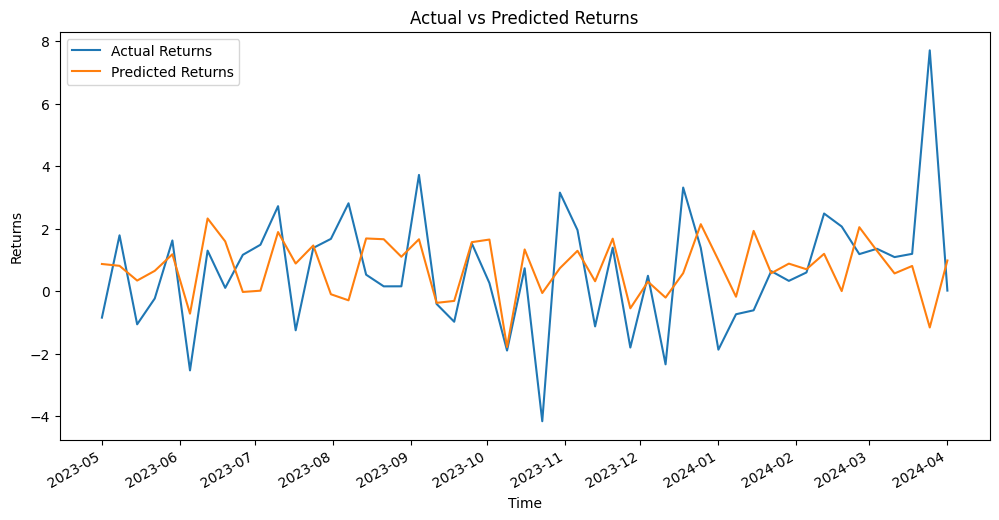

In [132]:
# Concatenate the DataFrames
df_combined = pd.concat([us_data_renamed,jp_data_renamed, in_data_renamed], axis=1)

# Convert index to datetime
df_combined.index = pd.to_datetime(df_combined.index)

# Remove duplicate columns
df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]

# Drop any rows with NaN values
df_combined.dropna(inplace=True)

# Extract features and target variable
X = df_combined.drop(columns=['India_Returns'])
y = df_combined['India_Returns']

# Perform normalization
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X)
y_normalized = scaler.fit_transform(y.values.reshape(-1, 1))  

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

# Reshape input data for LSTM
X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

# Define LSTM model
model = Sequential()
model.add(LSTM(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
model.add(Dense(units=1))  
model.compile(optimizer='adam', loss='mse')

# Train the model
model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=1)

# Evaluate the model
loss = model.evaluate(X_test, y_test)
print(f'Test Loss: {loss}')

# Make predictions
predictions = model.predict(X_test)
predictions = scaler.inverse_transform(predictions)

# Plot actual vs predicted returns
plt.figure(figsize=(12, 6))
plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
plt.title('Actual vs Predicted Returns')
plt.xlabel('Time')
plt.ylabel('Returns')
plt.legend()

# Setting x-axis to show monthly distribution
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.gcf().autofmt_xdate()  # Rotating dates for better readability

plt.show()


## THE SAME USING GRU

2/2 [==============================] - 0s 4ms/step - loss: 0.0057
Test Loss for INDIA: 0.0056529357098042965
2/2 [==============================] - 0s 5ms/step


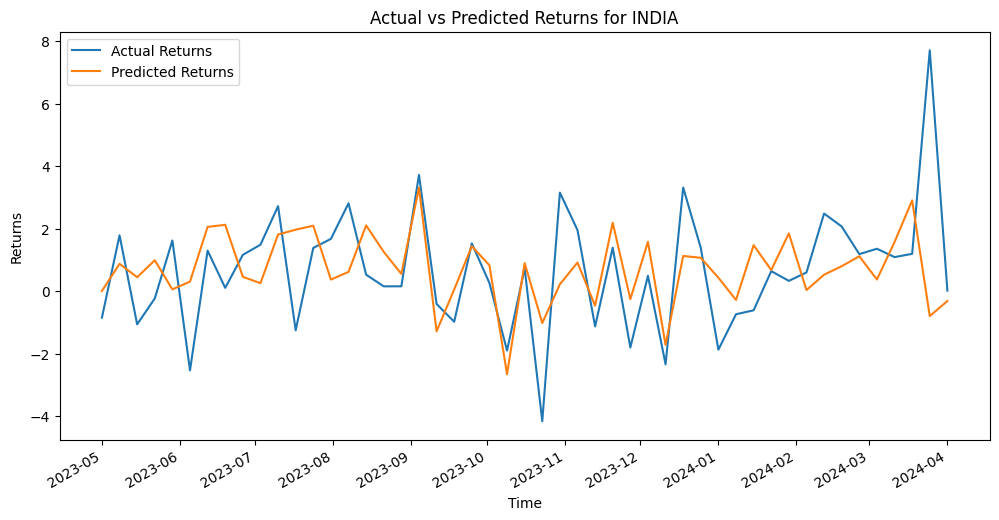

2/2 [==============================] - 0s 4ms/step - loss: 0.0109
Test Loss for JAPAN: 0.010863629169762135
2/2 [==============================] - 0s 6ms/step


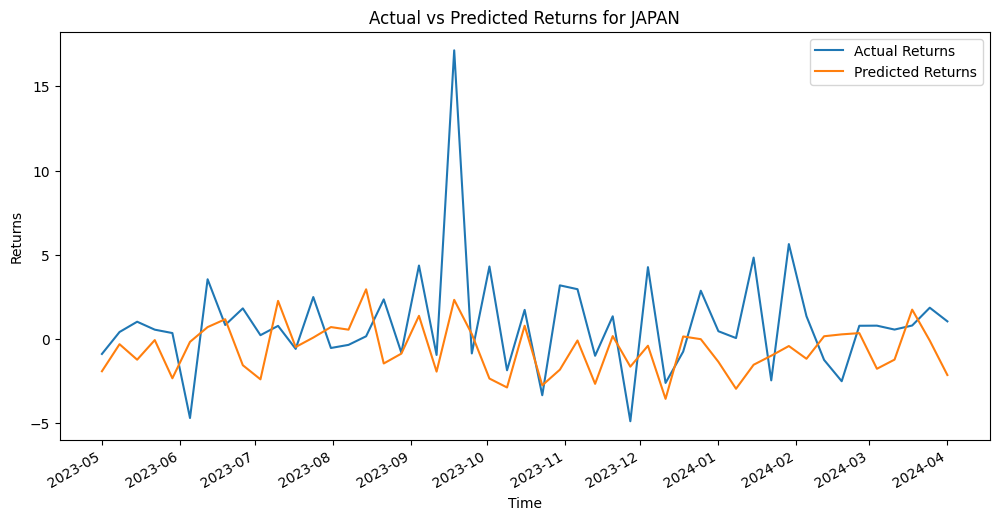

2/2 [==============================] - 0s 3ms/step - loss: 0.0056
Test Loss for US: 0.00557450857013464
2/2 [==============================] - 0s 2ms/step


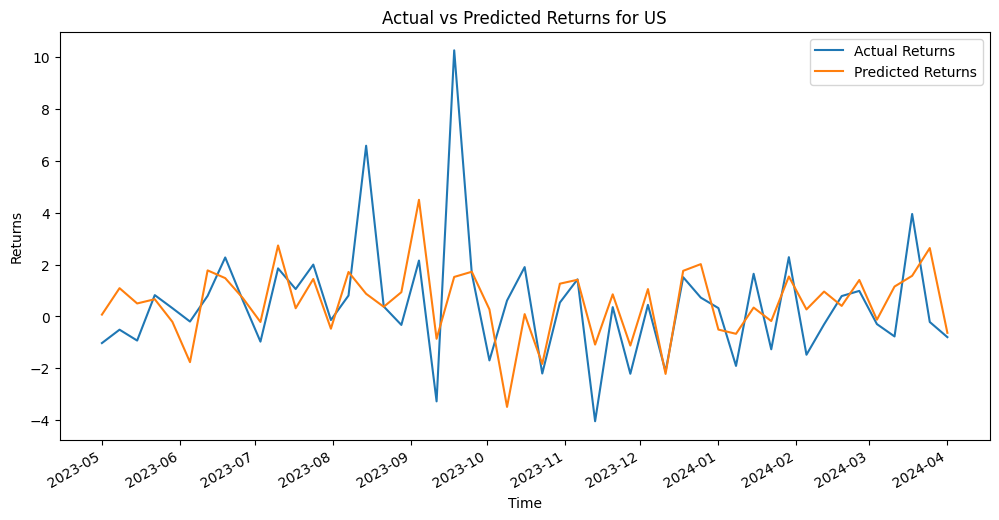

2/2 [==============================] - 1s 4ms/step - loss: 0.0043
Test Loss for UK: 0.004338596947491169
2/2 [==============================] - 0s 3ms/step


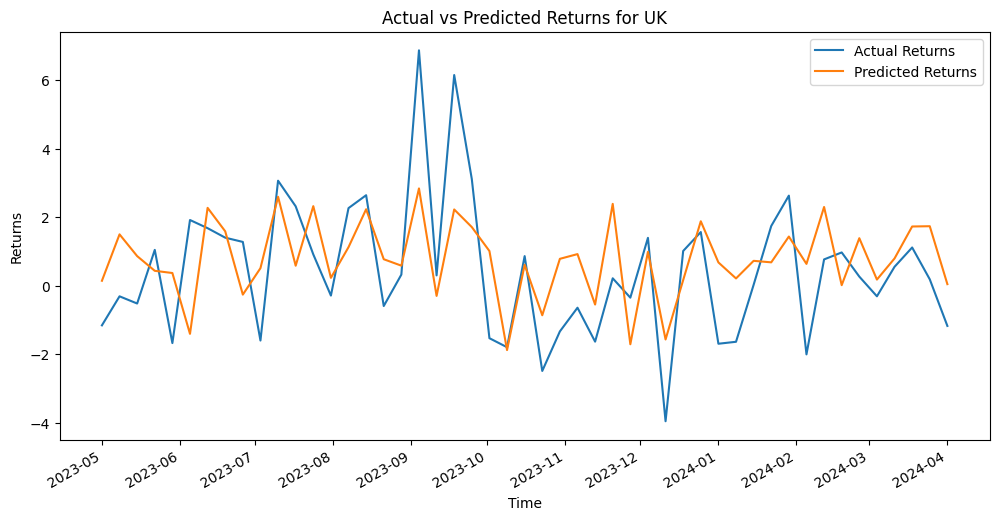

In [131]:
from keras.layers import GRU

# Function to train and evaluate GRU model
def train_evaluate_gru_model(data, target_country):
    # Combine data
    df_combined = pd.concat(data, axis=1)
    df_combined.index = pd.to_datetime(df_combined.index)
    df_combined = df_combined.loc[:, ~df_combined.columns.duplicated()]
    df_combined.dropna(inplace=True)

    # Drop specified columns from features
    features_to_drop = [f'{target_country}_{feature}' for feature in ['RSI', 'Stochastic_SlowK', 'Stochastic_SlowD', 'MACD', 'MACD_Signal', 'Bollinger_Upper', 'Bollinger_Lower', 'EMA', 'Returns']]
    X = df_combined.drop(columns=features_to_drop)
    
    # Target variable
    y = df_combined[f'{target_country}_Returns']

    # Normalize data
    scaler = MinMaxScaler()
    X_normalized = scaler.fit_transform(X)
    y_normalized = scaler.fit_transform(y.values.reshape(-1, 1))

    # Split dataset into training and testing sets
    X_train, X_test, y_train, y_test = train_test_split(X_normalized, y_normalized, test_size=0.2, random_state=42)

    # Reshape input data for GRU
    X_train = X_train.reshape((X_train.shape[0], 1, X_train.shape[1]))
    X_test = X_test.reshape((X_test.shape[0], 1, X_test.shape[1]))

    # Define GRU model
    model = Sequential()
    model.add(GRU(units=50, input_shape=(X_train.shape[1], X_train.shape[2])))
    model.add(Dense(units=1))
    model.compile(optimizer='adam', loss='mse')

    # Train the model
    model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

    # Evaluate the model
    loss = model.evaluate(X_test, y_test)
    print(f'Test Loss for {target_country.upper()}: {loss}')

    # Make predictions
    predictions = model.predict(X_test)
    predictions = scaler.inverse_transform(predictions)

    # Plot actual vs predicted returns
    plt.figure(figsize=(12, 6))
    plt.plot(df_combined.index[-len(y_test):], scaler.inverse_transform(y_test), label='Actual Returns')
    plt.plot(df_combined.index[-len(y_test):], predictions, label='Predicted Returns')
    plt.title(f'Actual vs Predicted Returns for {target_country.upper()}')
    plt.xlabel('Time')
    plt.ylabel('Returns')
    plt.legend()
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
    plt.gcf().autofmt_xdate()
    plt.show()

# Train and evaluate GRU models for each country
train_evaluate_gru_model([us_data_renamed, uk_data_renamed, jp_data_renamed, in_data_renamed], 'India')
train_evaluate_gru_model([uk_data_renamed, us_data_renamed, in_data_renamed, jp_data_renamed], 'Japan')
train_evaluate_gru_model([in_data_renamed, jp_data_renamed, uk_data_renamed, us_data_renamed], 'US')
train_evaluate_gru_model([in_data_renamed, jp_data_renamed, us_data_renamed, uk_data_renamed], 'UK')


In [1]:
## Error Dhundo ek stock ka dusre stock pe